In [13]:

import pandas as pd
train_df = pd.read_csv("../data/healthver_train.csv")
dev_df = pd.read_csv("../data/healthver_dev.csv")


In [14]:

def combine_text(df):
    return (
        "Claim: " + df["claim"] + " Evidence: " + df["evidence"]
    )

X_train = combine_text(train_df)
y_train = train_df["label"]

X_dev = combine_text(dev_df)
y_dev = dev_df["label"]


In [15]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Neutral','Refutes','Supports']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [16]:

from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_dev)

print("Validation accuracy:", accuracy_score(y_dev, y_pred))
print(classification_report(y_dev, y_pred, zero_division=0))


Validation accuracy: 0.6551904016692749
              precision    recall  f1-score   support

     Neutral       0.84      0.69      0.76       993
     Refutes       0.53      0.61      0.57       391
    Supports       0.50      0.62      0.56       533

    accuracy                           0.66      1917
   macro avg       0.63      0.64      0.63      1917
weighted avg       0.69      0.66      0.66      1917



Seems like with TF-IDF and linear regression model, is it not too great at predicting the correct labels given the claim + evidence:
**Recap**
1. Precision - Measures how often the model is correct when it predicts a label
* When my model predicts **Refute**, how often is it correct
* Ex: Model predicted refutes a total of 293 times, but 177 were correct 
* 177/293 --> 60.4% chance of model being correct if the model predicts refute

2. Recall - Measures how many actual examples of a category the model successfully identifies
* Out of all the actual **Refutes**, how many did my model correctly find
* Ex: Dataset has 391 refutes but model correctly identified 177
* 177/391 --> 45.3% of all refutes were correctly identified. 55% were wrong.

3. F1-Score - Represents how well the model is at finding the correct answers and avoiding incorrect predictions
* ~1 better || ~0.5 moderately precise || ~0.0 no good.

**Neutral: Best performance**
* F1-score = 0.77 --> Model is relatively effective at recognizing when scientific evidence doesn't directly support or contradict the claim

**Refutes: Worst Performance**
* F1-score = 0.52 --> 


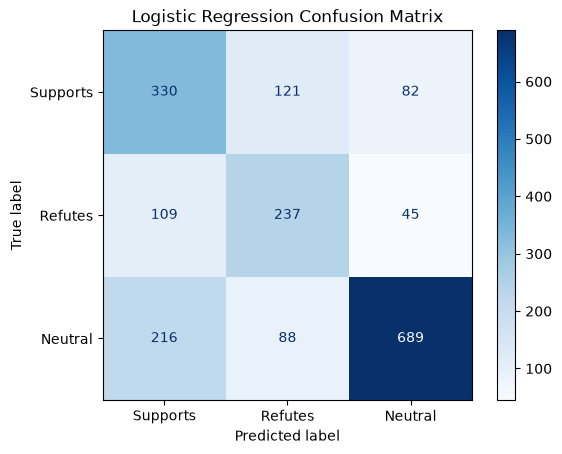

In [17]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_pred,
    labels=["Supports", "Refutes", "Neutral"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()


Demonstrates how well the Logistic regression model classified the 1,917 medical claim evidence pairs
Almost equal amount of support/refutes when actual label is refutes. Indicates that the model is struggling.

TLDR:
TF-IDF does not understand context. It identifies important words and phrases, but doesn't understand their meaning or how the two sentences relate to one another. Therefore, it may struggle to distingush supporting evidence from a contradictory evidence. This is supported by the fact that In the true label refutes, 146 actual refutes examples were incorrectly predicted as supports, suggesting that this model struggles with contradictions. 

Dataset is also a bit imbalanced (41.5% neutral 35.7% supports, 22.8% refutes label)

Experimental adjustments

Added class_weight="balanced" in Logistic Regression --> (Gives more weight to underrepresented categories during training) --> Model better at identifying contradictions --> Refutes increased from 0.45 -> .61

Experimenting with different n-gram ranges and class weighting showed that balanced class weights improved the model's ability to detect contradictory evidence. Specifically, Refutes recall increased from 0.43 to 0.61 using the (1,2) n-gram configuration and class_balance = "weighted". However, this came with a reduction in precision. Increasing the n-gram range to (1,4) did not consistently improve classification performance. Overall, the (1,2) n-gram configuration with balanced class weights achieved the highest macro-F1 score of 0.63.

In [18]:
test_df = pd.read_csv("../data/healthver_test.csv")

X_test = combine_text(test_df)
y_test = test_df["label"]

y_test_pred = model.predict(X_test)

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

     Neutral       0.76      0.72      0.74       727
     Refutes       0.49      0.63      0.55       425
    Supports       0.60      0.53      0.57       671

    accuracy                           0.63      1823
   macro avg       0.62      0.63      0.62      1823
weighted avg       0.64      0.63      0.63      1823

